<a href="https://colab.research.google.com/github/Rianfrancielton/IA-e-Matematica-Aplicada/blob/main/TDE_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TDE 4 -  IA
Equipe:

Gustavo Amorim Rodrigues

Rian Francielton Soares dos Santos

Artur do Nascimento Braga

Felipe Enzo de Sá Barreto Fernandes

João Pereira da Silva Filho

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
from google.colab import files

arquivo = files.upload()

df = pd.read_csv(next(iter(arquivo)))

df.head()

Saving train.csv to train.csv


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:
print("Tamanho do dataset:", df.shape)

print("\nInformações dos dados:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum().sum())

print("\nDistribuição da satisfação:")
print(df["satisfaction"].value_counts())

Tamanho do dataset: (103904, 25)

Informações dos dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-n

1. O que os resultados mostram?
- Quantidade de registros: 103.904 passageiros.
- Quantidade de colunas: 25.
- Valores ausentes: 310, todos na coluna Arrival Delay in Minutes.
- Passageiros neutros ou insatisfeitos: 58.879 (aproximadamente 56,66%).
- Passageiros satisfeitos: 45.025 (aproximadamente 43,34%).

Versão inicial do baseline. Nesta etapa, o preenchimento de valores ausentes e o get_dummies foram aplicados antes da divisão treino/teste. Na Etapa 3, o pré-processamento foi refeito dentro de um Pipeline, e os resultados desta etapa foram substituídos pelos da Etapa 3 (Random Forest: 96,38% de acurácia).

In [ ]:
# Remover colunas que não ajudam na previsão
df = df.drop(columns=["id", "Unnamed: 0"], errors="ignore")

# Separar as informações e a resposta
X = df.drop("satisfaction", axis=1)
y = df["satisfaction"]

# Preencher valores numéricos ausentes com a mediana
X = X.copy()

colunas_numericas = X.select_dtypes(include="number").columns
X[colunas_numericas] = X[colunas_numericas].fillna(
    X[colunas_numericas].median()
)

# Transformar textos em números
X = pd.get_dummies(X, drop_first=True)

print("Dados preparados:", X.shape)

Dados preparados: (103904, 23)


In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_treino.shape)
print("Dados de teste:", X_teste.shape)

Dados de treinamento: (83123, 23)
Dados de teste: (20781, 23)


O random_state=42 ajuda a reproduzir a mesma divisão dos dados. Já o stratify=y mantém aproximadamente a mesma proporção de cada classe nos dois conjuntos.

In [ ]:
modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X_treino, y_treino)

previsoes = modelo.predict(X_teste)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [ ]:
resultados = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Acurácia balanceada",
        "Precisão",
        "Recall",
        "F1-score"
    ],
    "Resultado": [
        accuracy_score(y_teste, previsoes),
        balanced_accuracy_score(y_teste, previsoes),
        precision_score(y_teste, previsoes, pos_label="satisfied"),
        recall_score(y_teste, previsoes, pos_label="satisfied"),
        f1_score(y_teste, previsoes, pos_label="satisfied")
    ]
})

resultados["Resultado"] = (
    resultados["Resultado"] * 100
).round(2)

print(resultados.to_string(index=False))


            Métrica  Resultado
           Acurácia      94.40
Acurácia balanceada      94.37
           Precisão      93.08
             Recall      94.08
           F1-score      93.58


Acurácia de 94,40%: o modelo acertou aproximadamente 94 de cada 100 previsões.

Acurácia balanceada de 94,37%: o desempenho médio entre as duas classes também foi alto.

Precisão de 93,08%: entre os passageiros previstos como satisfeitos, aproximadamente 93% realmente estavam satisfeitos.

Recall de 94,08%: o modelo identificou aproximadamente 94% dos passageiros que realmente estavam satisfeitos.

F1-score de 93,58%: mostra um bom equilíbrio entre precisão e recall.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_treino, y_treino)

previsoes_rf = modelo_rf.predict(X_teste)

print("Random Forest treinada com sucesso!")

Random Forest treinada com sucesso!


In [ ]:
comparacao = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Acurácia balanceada",
        "Precisão",
        "Recall",
        "F1-score"
    ],
    "Árvore de Decisão": [
        accuracy_score(y_teste, previsoes),
        balanced_accuracy_score(y_teste, previsoes),
        precision_score(y_teste, previsoes, pos_label="satisfied"),
        recall_score(y_teste, previsoes, pos_label="satisfied"),
        f1_score(y_teste, previsoes, pos_label="satisfied")
    ],
    "Random Forest": [
        accuracy_score(y_teste, previsoes_rf),
        balanced_accuracy_score(y_teste, previsoes_rf),
        precision_score(y_teste, previsoes_rf, pos_label="satisfied"),
        recall_score(y_teste, previsoes_rf, pos_label="satisfied"),
        f1_score(y_teste, previsoes_rf, pos_label="satisfied")
    ]
})

comparacao[["Árvore de Decisão", "Random Forest"]] = (
    comparacao[["Árvore de Decisão", "Random Forest"]] * 100
).round(2)

print(comparacao.to_string(index=False))

            Métrica  Árvore de Decisão  Random Forest
           Acurácia              94.40          96.19
Acurácia balanceada              94.37          95.98
           Precisão              93.08          96.73
             Recall              94.08          94.39
           F1-score              93.58          95.55


In [ ]:
print("Árvore de Decisão")
print(confusion_matrix(y_teste, previsoes))
print(classification_report(y_teste, previsoes))

print("Random Forest")
print(confusion_matrix(y_teste, previsoes_rf))
print(classification_report(y_teste, previsoes_rf))

Árvore de Decisão
[[11146   630]
 [  533  8472]]
                         precision    recall  f1-score   support

neutral or dissatisfied       0.95      0.95      0.95     11776
              satisfied       0.93      0.94      0.94      9005

               accuracy                           0.94     20781
              macro avg       0.94      0.94      0.94     20781
           weighted avg       0.94      0.94      0.94     20781

Random Forest
[[11489   287]
 [  505  8500]]
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.98      0.97     11776
              satisfied       0.97      0.94      0.96      9005

               accuracy                           0.96     20781
              macro avg       0.96      0.96      0.96     20781
           weighted avg       0.96      0.96      0.96     20781



### Discussão dos resultados

Foram utilizados dois algoritmos com as configurações padrão do Scikit-learn: Árvore de Decisão e Random Forest. Os dados foram divididos em 80% para treinamento e 20% para teste.

A Random Forest apresentou os melhores resultados, com 96,19% de acurácia e 95,98% de acurácia balanceada. Já a Árvore de Decisão obteve 94,40% de acurácia e 94,37% de acurácia balanceada.

Os resultados mostram que os dois modelos tiveram um bom desempenho, mas a Random Forest apresentou melhores resultados nas métricas avaliadas. Por isso, sua acurácia balanceada de 95,98% será usada como referência para comparar os resultados dos modelos nas próximas etapas.

### Resultados do Baseline

Foram utilizados os algoritmos Árvore de Decisão e Random Forest, com as configurações padrão do Scikit-learn. Os dados foram divididos em 80% para treinamento e 20% para teste.

A Árvore de Decisão obteve 94,40% de acurácia e 94,37% de acurácia balanceada. Já a Random Forest alcançou 96,19% de acurácia e 95,98% de acurácia balanceada. A Random Forest também apresentou melhores resultados em precisão, recall e F1-score.

Com isso, a Random Forest teve o melhor desempenho geral, e sua acurácia balanceada de 95,98% será usada como referência para as próximas etapas do projeto.

#**ETAPA** 2

#Teste dos três tipos de kernel

O SVM foi testado com três tipos de kernel: linear, RBF e polinomial. O kernel linear busca separar as classes por uma fronteira linear, enquanto o RBF permite representar separações não lineares e o polinomial utiliza relações polinomiais. O objetivo foi comparar o desempenho dos três kernels para identificar qual apresentou os melhores resultados na classificação dos passageiros.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

# Usar uma amostra dos dados de treinamento
X_amostra = X_treino.sample(
    n=min(10000, len(X_treino)), random_state=42
)
y_amostra = y_treino.loc[X_amostra.index]

resultados_svm = []
modelos_svm = {}

# Testar os três kernels
for kernel in ["linear", "rbf", "poly"]:

    pipeline = Pipeline([
        ("escala", StandardScaler()),
        ("svm", SVC(kernel=kernel))
    ])

    parametros = {"svm__C": [0.1, 1, 10]}

    if kernel in ["rbf", "poly"]:
        parametros["svm__gamma"] = ["scale", 0.01, 0.1]

    busca = GridSearchCV(
        pipeline,
        parametros,
        cv=3,
        scoring="balanced_accuracy",
        n_jobs=-1,
        verbose=1
    )

    busca.fit(X_amostra, y_amostra)

    modelos_svm[kernel] = busca.best_estimator_
    previsoes = busca.best_estimator_.predict(X_teste)

    resultados_svm.append({
        "Kernel": kernel,
        "Melhores parâmetros": busca.best_params_,
        "Acurácia (%)": round(
            accuracy_score(y_teste, previsoes) * 100, 2
        ),
        "Acurácia balanceada (%)": round(
            balanced_accuracy_score(y_teste, previsoes) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(
                y_teste, previsoes, pos_label="satisfied"
            ) * 100, 2
        )
    })

tabela_svm = pd.DataFrame(resultados_svm)
display(tabela_svm)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Fitting 3 folds for each of 9 candidates, totalling 27 fits


,Kernel,Melhores parâmetros,Acurácia (%),Acurácia balanceada (%),F1-score (%)
0,linear,{'svm__C': 0.1},87.85,87.32,85.60
1,rbf,"{'svm__C': 10, 'svm__gamma': 'scale'}",94.41,94.25,93.52
2,poly,"{'svm__C': 1, 'svm__gamma': 0.1}",92.33,92.08,91.07


O código testa os kernels linear, RBF e polinomial. Para cada um, o GridSearchCV experimenta diferentes valores de C e, quando aplicável, de gamma. A busca utiliza validação cruzada com três divisões e seleciona a configuração com a melhor acurácia balanceada. Ao final, são apresentados os melhores parâmetros e as métricas de cada kernel.

## 2. Melhores parâmetros encontrados

Após a busca com GridSearchCV, foram identificadas as melhores configurações para cada kernel. O kernel linear apresentou C = 0,1; o RBF apresentou C = 10 e gamma = scale; e o polinomial apresentou C = 1 e gamma = 0,1. Entre os modelos testados, o RBF obteve o melhor resultado.

In [ ]:
display(
    tabela_svm[
        ["Kernel", "Melhores parâmetros",
         "Acurácia (%)", "Acurácia balanceada (%)", "F1-score (%)"]
    ]
)

,Kernel,Melhores parâmetros,Acurácia (%),Acurácia balanceada (%),F1-score (%)
0,linear,{'svm__C': 0.1},87.85,87.32,85.60
1,rbf,"{'svm__C': 10, 'svm__gamma': 'scale'}",94.41,94.25,93.52
2,poly,"{'svm__C': 1, 'svm__gamma': 0.1}",92.33,92.08,91.07


A tabela permite comparar o desempenho dos três kernels. O RBF alcançou 94,41% de acurácia, 94,25% de acurácia balanceada e 93,52% de F1-score, apresentando os melhores resultados entre as configurações testadas.

## 3. Visualização dos vetores de suporte

Os vetores de suporte são os pontos que ajudam o SVM a definir a fronteira de decisão entre as classes. Para visualizar esses pontos, foi utilizada a técnica PCA, que representa os dados em duas dimensões. O gráfico destaca os vetores de suporte com círculos pretos.

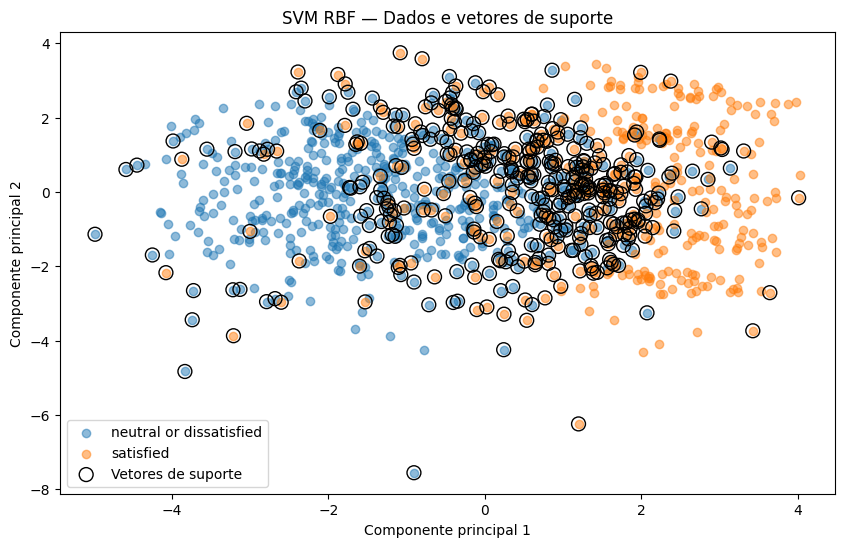

Quantidade de vetores de suporte: 421


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Selecionar até 1000 registros
X_grafico = X_amostra.sample(
    n=min(1000, len(X_amostra)), random_state=42
)
y_grafico = y_amostra.loc[X_grafico.index]

# Padronizar os dados
escala = StandardScaler()
X_escala = escala.fit_transform(X_grafico)

# Reduzir para duas dimensões
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_escala)

# Treinar SVM na projeção de duas dimensões
modelo_grafico = SVC(
    kernel="rbf", C=10, gamma="scale"
)
modelo_grafico.fit(X_2d, y_grafico)

vetores = modelo_grafico.support_vectors_

# Criar o gráfico
plt.figure(figsize=(10, 6))

for classe in y_grafico.unique():
    mascara = y_grafico.to_numpy() == classe
    plt.scatter(
        X_2d[mascara, 0],
        X_2d[mascara, 1],
        label=classe,
        alpha=0.5
    )

plt.scatter(
    vetores[:, 0],
    vetores[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    label="Vetores de suporte"
)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("SVM RBF — Dados e vetores de suporte")
plt.legend()
plt.show()

print("Quantidade de vetores de suporte:", len(vetores))

O gráfico representa os dados em duas dimensões após a aplicação do PCA. Os círculos pretos identificam os vetores de suporte do modelo treinado nessa projeção. Foram encontrados 421 vetores de suporte nessa visualização. Esse número corresponde ao modelo do gráfico, que utiliza duas dimensões e uma amostra de até 1.000 registros.

## 4. Comparação entre OvO e OvA

One-vs-One (OvO) compara as classes em pares, enquanto One-vs-All (OvA) treina classificadores para separar cada classe das demais. As duas estratégias foram testadas utilizando o SVM com kernel RBF e os parâmetros escolhidos pelo GridSearchCV.

In [ ]:
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.base import clone

modelo_base = Pipeline([
    ("escala", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=10, gamma="scale"))
])

modelos_estrategias = {
    "OvO": OneVsOneClassifier(clone(modelo_base)),
    "OvA": OneVsRestClassifier(clone(modelo_base))
}

resultados_estrategias = []

for nome, modelo in modelos_estrategias.items():
    modelo.fit(X_amostra, y_amostra)
    previsoes = modelo.predict(X_teste)

    resultados_estrategias.append({
        "Estratégia": nome,
        "Acurácia (%)": round(
            accuracy_score(y_teste, previsoes) * 100, 2
        ),
        "Acurácia balanceada (%)": round(
            balanced_accuracy_score(y_teste, previsoes) * 100, 2
        ),
        "F1-score (%)": round(
            f1_score(
                y_teste, previsoes, pos_label="satisfied"
            ) * 100, 2
        )
    })

tabela_estrategias = pd.DataFrame(resultados_estrategias)
display(tabela_estrategias)

,Estratégia,Acurácia (%),Acurácia balanceada (%),F1-score (%)
0,OvO,94.41,94.25,93.52
1,OvA,94.41,94.25,93.52


#ETAPA 3 — Padronização dos experimentos

In [ ]:
# Importar bibliotecas
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Remover colunas que não ajudam na previsão
dados = df.drop(
    columns=["id", "Unnamed: 0"],
    errors="ignore"
).copy()

# Separar características e variável-alvo
X = dados.drop("satisfaction", axis=1)
y = dados["satisfaction"]

# Identificar colunas numéricas e categóricas
colunas_numericas = X.select_dtypes(
    include=np.number
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Colunas numéricas:", len(colunas_numericas))
print("Colunas categóricas:", len(colunas_categoricas))

# Dividir os dados em treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTreinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

print("\nDistribuição no treinamento:")
print(y_treino.value_counts(normalize=True) * 100)

print("\nDistribuição no teste:")
print(y_teste.value_counts(normalize=True) * 100)

Colunas numéricas: 18
Colunas categóricas: 4

Treinamento: (83123, 22)
Teste: (20781, 22)

Distribuição no treinamento:
satisfaction
neutral or dissatisfied    56.666627
satisfied                  43.333373
Name: proportion, dtype: float64

Distribuição no teste:
satisfaction
neutral or dissatisfied    56.667148
satisfied                  43.332852
Name: proportion, dtype: float64


In [ ]:
# Tratamento das colunas numéricas
transformacao_numerica = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler())
])

# Tratamento das colunas categóricas
transformacao_categorica = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar as transformações
preprocessamento = ColumnTransformer([
    ("numericas", transformacao_numerica, colunas_numericas),
    ("categoricas", transformacao_categorica, colunas_categoricas)
])

print("Pré-processamento configurado!")

Pré-processamento configurado!


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Criar os modelos
modelos = {
    "Árvore de Decisão": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )
}

resultados = []

# Treinar e avaliar os modelos
for nome, algoritmo in modelos.items():

    pipeline = Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", algoritmo)
    ])

    pipeline.fit(X_treino, y_treino)

    previsoes = pipeline.predict(X_teste)

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsoes),
        "Acurácia balanceada": balanced_accuracy_score(
            y_teste, previsoes
        ),
        "Precisão": precision_score(
            y_teste, previsoes, pos_label="satisfied"
        ),
        "Recall": recall_score(
            y_teste, previsoes, pos_label="satisfied"
        ),
        "F1-score": f1_score(
            y_teste, previsoes, pos_label="satisfied"
        )
    })

# Criar tabela comparativa
tabela_baseline = pd.DataFrame(resultados)

colunas_metricas = [
    "Acurácia",
    "Acurácia balanceada",
    "Precisão",
    "Recall",
    "F1-score"
]

tabela_baseline[colunas_metricas] = (
    tabela_baseline[colunas_metricas] * 100
).round(2)

display(tabela_baseline)

,Modelo,Acurácia,Acurácia balanceada,Precisão,Recall,F1-score
0,Árvore de Decisão,94.59,94.58,93.10,94.53,93.81
1,Random Forest,96.38,96.17,96.95,94.61,95.77


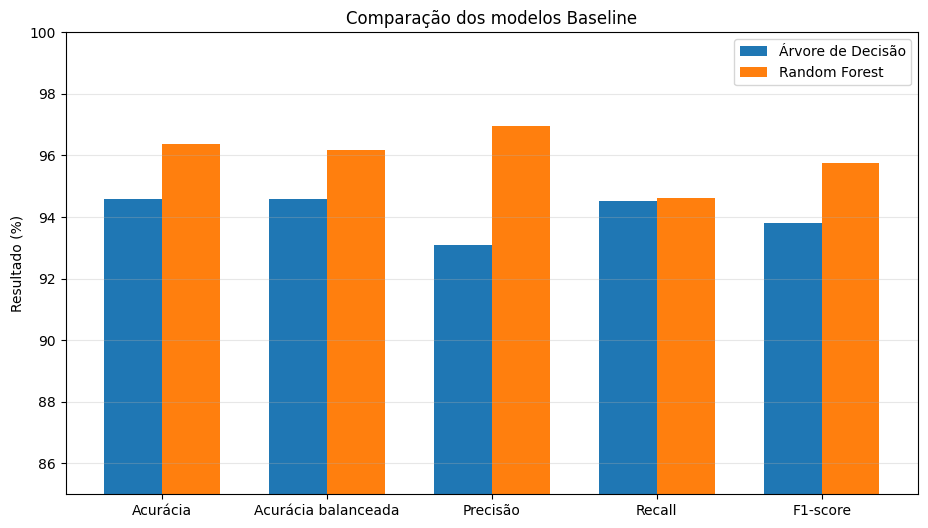

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metricas = [
    "Acurácia",
    "Acurácia balanceada",
    "Precisão",
    "Recall",
    "F1-score"
]

arvore = [94.59, 94.58, 93.10, 94.53, 93.81]
floresta = [96.38, 96.17, 96.95, 94.61, 95.77]

x = np.arange(len(metricas))
largura = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - largura/2,
    arvore,
    largura,
    label="Árvore de Decisão"
)

plt.bar(
    x + largura/2,
    floresta,
    largura,
    label="Random Forest"
)

plt.ylabel("Resultado (%)")
plt.title("Comparação dos modelos Baseline")
plt.xticks(x, metricas)
plt.ylim(85, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### Discussão dos resultados do Baseline

Após a correção do pré-processamento, os modelos Árvore de Decisão e Random Forest foram treinados e avaliados utilizando a mesma divisão dos dados, com 80% para treinamento e 20% para teste.

A Árvore de Decisão apresentou 94,59% de acurácia e 93,81% de F1-score. Já a Random Forest alcançou 96,38% de acurácia e 95,77% de F1-score, apresentando os melhores resultados em todas as métricas avaliadas.

A Random Forest também obteve 96,95% de precisão, demonstrando um bom desempenho ao identificar passageiros satisfeitos. Dessa forma, esse algoritmo permanece como o melhor modelo do baseline e será utilizado como referência para as próximas comparações.

###ETAPA 4 — Rede Neural (MLP)

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Bibliotecas da Rede Neural importadas!")

Bibliotecas da Rede Neural importadas!


4.1 — Treinamento da Rede Neural

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

modelo_mlp = Pipeline([
    ("preprocessamento", preprocessamento),

    ("modelo", MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        max_iter=150,
        random_state=42,
        early_stopping=False,
        learning_rate_init=0.001
    ))
])

modelo_mlp.fit(X_treino, y_treino)

print("Rede Neural treinada com sucesso!")

Rede Neural treinada com sucesso!


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


4.2 — Realizar previsões

In [ ]:
previsoes_mlp = modelo_mlp.predict(X_teste)

print("Previsões realizadas!")
print(previsoes_mlp[:10])

Previsões realizadas!
['neutral or dissatisfied' 'neutral or dissatisfied' 'satisfied'
 'neutral or dissatisfied' 'neutral or dissatisfied'
 'neutral or dissatisfied' 'satisfied' 'neutral or dissatisfied'
 'satisfied' 'satisfied']


depois do treinamento, a rede recebe os dados de teste e tenta prever a satisfação dos passageiros.

4.3 — Avaliar o desempenho

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resultados_mlp = {
    "Modelo": "Rede Neural MLP",

    "Acurácia": accuracy_score(
        y_teste, previsoes_mlp
    ) * 100,

    "Acurácia balanceada": balanced_accuracy_score(
        y_teste, previsoes_mlp
    ) * 100,

    "Precisão": precision_score(
        y_teste, previsoes_mlp,
        pos_label="satisfied"
    ) * 100,

    "Recall": recall_score(
        y_teste, previsoes_mlp,
        pos_label="satisfied"
    ) * 100,

    "F1-score": f1_score(
        y_teste, previsoes_mlp,
        pos_label="satisfied"
    ) * 100
}

tabela_mlp = pd.DataFrame([resultados_mlp])

metricas = [
    "Acurácia",
    "Acurácia balanceada",
    "Precisão",
    "Recall",
    "F1-score"
]

tabela_mlp[metricas] = tabela_mlp[metricas].round(2)

display(tabela_mlp)

,Modelo,Acurácia,Acurácia balanceada,Precisão,Recall,F1-score
0,Rede Neural MLP,95.42,95.37,94.52,94.95,94.73


4.4 — Matriz de confusão
Agora vamos visualizar os acertos e erros da Rede Neural.

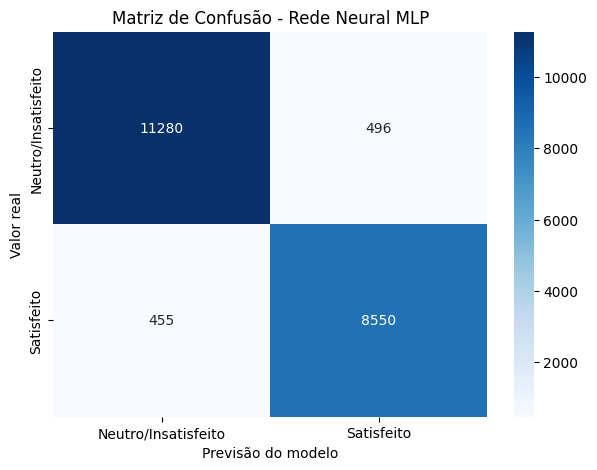

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    y_teste,
    previsoes_mlp,
    labels=["neutral or dissatisfied", "satisfied"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Neutro/Insatisfeito",
        "Satisfeito"
    ],
    yticklabels=[
        "Neutro/Insatisfeito",
        "Satisfeito"
    ]
)

plt.xlabel("Previsão do modelo")
plt.ylabel("Valor real")
plt.title("Matriz de Confusão - Rede Neural MLP")

plt.show()

4.5 — Verificar o treinamento da Rede Neural

In [ ]:
rede = modelo_mlp.named_steps["modelo"]

print("Quantidade de iterações:", rede.n_iter_)
print("Quantidade de camadas:", rede.n_layers_)
print("Quantidade de saídas:", rede.n_outputs_)
print("Melhor perda de treino::", rede.best_loss_)

Quantidade de iterações: 150
Quantidade de camadas: 4
Quantidade de saídas: 1
Melhor perda de treino:: 0.04276254482252933


4.6 — Comparar Rede Neural com Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

modelo_rf_final = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf_final.fit(X_treino, y_treino)

previsoes_rf_novo = modelo_rf_final.predict(X_teste)

print("Random Forest treinada novamente!")

Random Forest treinada novamente!


MLP original -> treino: 98.49% | teste: 95.42%


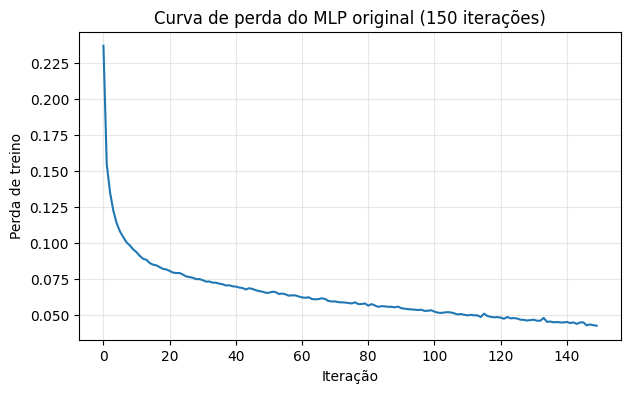

,Camadas,alpha,Validação interna (%),Acurácia teste (%),Acurácia balanceada (%)
2,"(100, 50)",0.00,96.15,96.18,95.88
3,"(100, 50)",0.01,96.10,96.08,95.75
5,"(128, 64, 32)",0.01,96.05,96.13,95.82
4,"(128, 64, 32)",0.00,95.95,95.88,95.77
0,"(64,)",0.00,95.72,95.59,95.39
1,"(64,)",0.01,95.68,95.45,95.27


In [ ]:
import matplotlib.pyplot as plt

# Diagnóstico do MLP original
acc_treino = accuracy_score(y_treino, modelo_mlp.predict(X_treino)) * 100
acc_teste = accuracy_score(y_teste, previsoes_mlp) * 100
print(f"MLP original -> treino: {acc_treino:.2f}% | teste: {acc_teste:.2f}%")

rede = modelo_mlp.named_steps["modelo"]
plt.figure(figsize=(7, 4))
plt.plot(rede.loss_curve_)
plt.xlabel("Iteração"); plt.ylabel("Perda de treino")
plt.title("Curva de perda do MLP original (150 iterações)")
plt.grid(alpha=0.3); plt.show()

# Alvo numérico só para este experimento (1 = satisfied, 0 = neutral or dissatisfied)
y_treino_num = (y_treino == "satisfied").astype(int)
y_teste_num = (y_teste == "satisfied").astype(int)

configs = {"(64,)": (64,), "(100, 50)": (100, 50), "(128, 64, 32)": (128, 64, 32)}
linhas_mlp = []
for nome, camadas in configs.items():
    for alpha in [1e-4, 1e-2]:
        pipe = Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", MLPClassifier(hidden_layer_sizes=camadas, alpha=alpha,
                                     early_stopping=True, max_iter=300,
                                     random_state=42))
        ])
        pipe.fit(X_treino, y_treino_num)
        prev = pipe.predict(X_teste)
        linhas_mlp.append({
            "Camadas": nome, "alpha": alpha,
            "Validação interna (%)": pipe.named_steps["modelo"].best_validation_score_ * 100,
            "Acurácia teste (%)": accuracy_score(y_teste_num, prev) * 100,
            "Acurácia balanceada (%)": balanced_accuracy_score(y_teste_num, prev) * 100,
        })
display(pd.DataFrame(linhas_mlp).round(2).sort_values("Validação interna (%)", ascending=False))

In [ ]:
comparacao_mlp = pd.DataFrame([
    {
        "Modelo": "Random Forest",
        "Acurácia": accuracy_score(
            y_teste, previsoes_rf_novo
        ) * 100
    },
    {
        "Modelo": "Rede Neural MLP",
        "Acurácia": accuracy_score(
            y_teste, previsoes_mlp
        ) * 100
    }
])

display(comparacao_mlp.round(2))

,Modelo,Acurácia
0,Random Forest,96.38
1,Rede Neural MLP,95.42


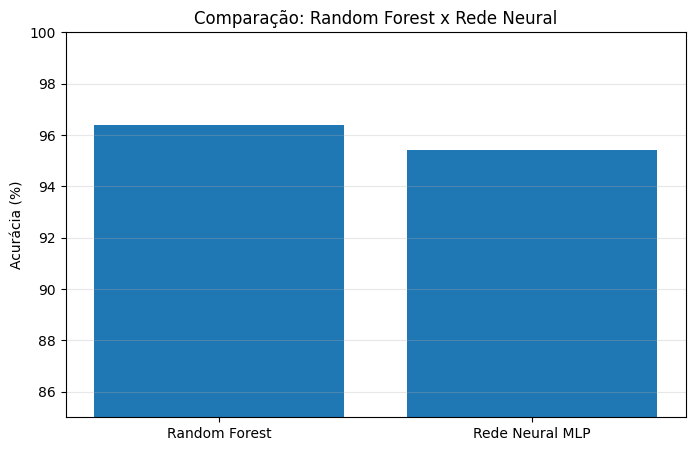

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparacao_mlp["Modelo"],
    comparacao_mlp["Acurácia"]
)

plt.ylabel("Acurácia (%)")
plt.title("Comparação: Random Forest x Rede Neural")
plt.ylim(85, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

O modelo Random Forest apresentou a melhor acurácia, alcançando 96,38%, enquanto a Rede Neural MLP obteve 95,42%. Os dois modelos conseguiram bons resultados na classificação da satisfação dos passageiros. Entretanto, o Random Forest apresentou um desempenho ligeiramente superior nesse experimento, sendo o modelo com maior acurácia entre os dois avaliados.

In [ ]:
comparacao_final = pd.DataFrame([
    {"Modelo": "Decision Tree", "Acurácia": 94.59},
    {"Modelo": "Random Forest", "Acurácia": 96.38},
    {"Modelo": "SVM (RBF)", "Acurácia": 94.41},
    {"Modelo": "Rede Neural MLP", "Acurácia": 95.42}
])

comparacao_final = comparacao_final.sort_values(
    by="Acurácia", ascending=False
)

display(comparacao_final)

,Modelo,Acurácia
1,Random Forest,96.38
3,Rede Neural MLP,95.42
0,Decision Tree,94.59
2,SVM (RBF),94.41


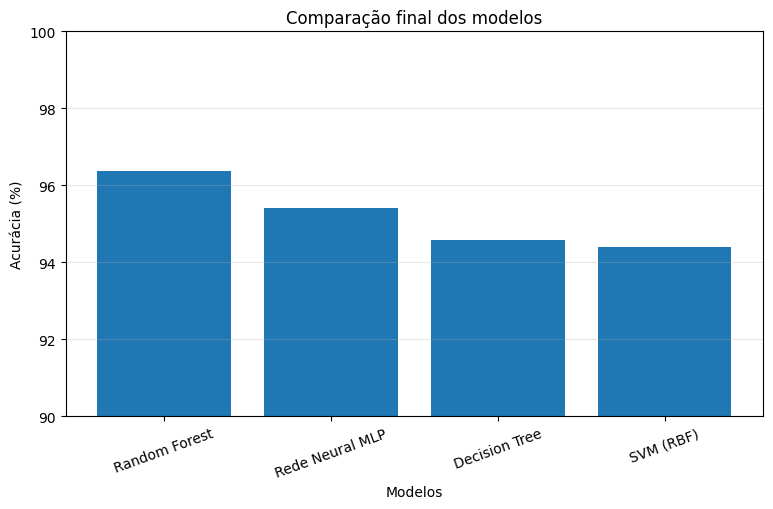

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparacao_final["Modelo"],
    comparacao_final["Acurácia"]
)

plt.title("Comparação final dos modelos")
plt.xlabel("Modelos")
plt.ylabel("Acurácia (%)")
plt.ylim(90, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score)
import pandas as pd

novos = {
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Regressão Logística": LogisticRegression(max_iter=1000),
}

linhas = []
for nome, algoritmo in novos.items():
    pipe = Pipeline([("preprocessamento", preprocessamento),
                     ("modelo", algoritmo)])
    pipe.fit(X_treino, y_treino)
    prev = pipe.predict(X_teste)
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, prev) * 100,
        "Acurácia balanceada": balanced_accuracy_score(y_teste, prev) * 100,
        "Precisão": precision_score(y_teste, prev, pos_label="satisfied") * 100,
        "Recall": recall_score(y_teste, prev, pos_label="satisfied") * 100,
        "F1-score": f1_score(y_teste, prev, pos_label="satisfied") * 100,
    })

display(pd.DataFrame(linhas).round(2))

,Modelo,Acurácia,Acurácia balanceada,Precisão,Recall,F1-score
0,Gradient Boosting,96.52,96.29,97.30,94.58,95.92
1,KNN,92.96,92.51,94.23,89.21,91.65
2,Regressão Logística,87.65,87.24,86.92,84.18,85.52


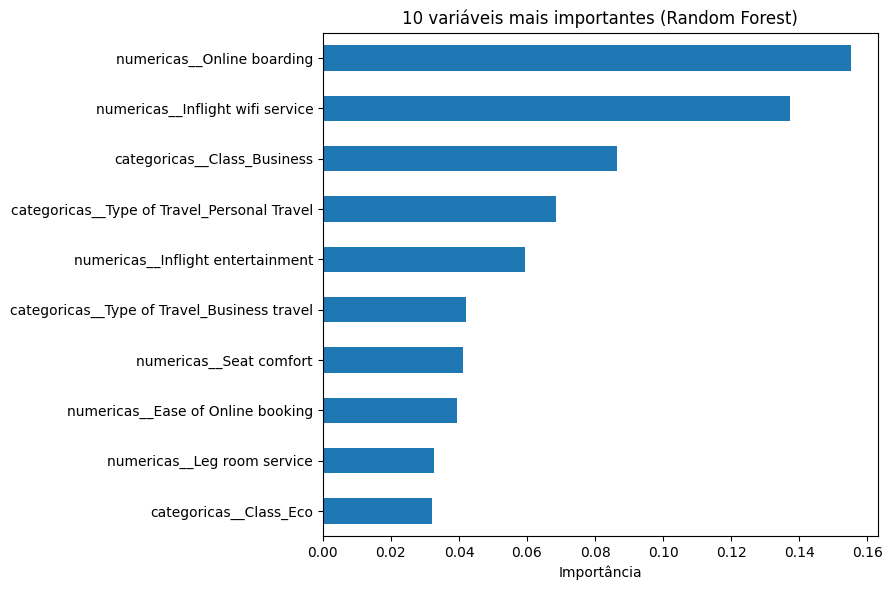

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

nomes = modelo_rf_final.named_steps["preprocessamento"].get_feature_names_out()
imp = pd.Series(
    modelo_rf_final.named_steps["modelo"].feature_importances_,
    index=nomes
).sort_values(ascending=False).head(10)

imp.sort_values().plot(kind="barh", figsize=(9, 6))
plt.xlabel("Importância")
plt.title("10 variáveis mais importantes (Random Forest)")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

arquivo = files.upload()
df = pd.read_csv(next(iter(arquivo)))

dados = df.drop(columns=["id", "Unnamed: 0"], errors="ignore").copy()
X = dados.drop("satisfaction", axis=1)
y = dados["satisfaction"]

colunas_numericas = X.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

transformacao_numerica = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler())
])
transformacao_categorica = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])
preprocessamento = ColumnTransformer([
    ("numericas", transformacao_numerica, colunas_numericas),
    ("categoricas", transformacao_categorica, colunas_categoricas)
])

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)

Saving train.csv to train (1).csv
Treino: (83123, 22) | Teste: (20781, 22)


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

y_treino_num = (y_treino == "satisfied").astype(int)
y_teste_num = (y_teste == "satisfied").astype(int)

modelos_rapidos = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Gradient Boosting (Hist)": HistGradientBoostingClassifier(random_state=42),
    "Rede Neural MLP (ajustada)": MLPClassifier(hidden_layer_sizes=(100, 50),
                                                early_stopping=True, max_iter=300,
                                                random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Regressão Logística": LogisticRegression(max_iter=1000),
}

pipes_finais, linhas = {}, []
for nome, algoritmo in modelos_rapidos.items():
    pipe = Pipeline([("preprocessamento", preprocessamento), ("modelo", algoritmo)])
    pipe.fit(X_treino, y_treino_num)
    pipes_finais[nome] = pipe
    prev = pipe.predict(X_teste)
    score = pipe.predict_proba(X_teste)[:, 1]
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste_num, prev) * 100,
        "Acurácia balanceada": balanced_accuracy_score(y_teste_num, prev) * 100,
        "F1-score": f1_score(y_teste_num, prev) * 100,
        "ROC AUC": roc_auc_score(y_teste_num, score) * 100,
    })
    print("pronto:", nome)

display(pd.DataFrame(linhas).round(2).sort_values("Acurácia balanceada", ascending=False))

pronto: Decision Tree
pronto: Random Forest
pronto: Gradient Boosting (Hist)
pronto: Rede Neural MLP (ajustada)
pronto: KNN
pronto: Regressão Logística


,Modelo,Acurácia,Acurácia balanceada,F1-score,ROC AUC
2,Gradient Boosting (Hist),96.52,96.29,95.92,99.51
1,Random Forest,96.38,96.17,95.77,99.41
3,Rede Neural MLP (ajustada),96.18,95.88,95.50,99.42
0,Decision Tree,94.59,94.58,93.81,94.58
4,KNN,92.96,92.51,91.65,97.10
5,Regressão Logística,87.65,87.24,85.52,92.81


In [ ]:
import time
from sklearn.svm import SVC

amostra = X_treino.sample(n=30000, random_state=42)
y_amostra_num = y_treino_num.loc[amostra.index]

t0 = time.time()
pipe_svm = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", SVC(kernel="rbf", C=10, gamma="scale"))
])
pipe_svm.fit(amostra, y_amostra_num)
prev = pipe_svm.predict(X_teste)
score = pipe_svm.decision_function(X_teste)

pipes_finais["SVM (RBF)"] = pipe_svm
linhas.append({
    "Modelo": "SVM (RBF, 30 mil)",
    "Acurácia": accuracy_score(y_teste_num, prev) * 100,
    "Acurácia balanceada": balanced_accuracy_score(y_teste_num, prev) * 100,
    "F1-score": f1_score(y_teste_num, prev) * 100,
    "ROC AUC": roc_auc_score(y_teste_num, score) * 100,
})
print(f"SVM pronto em {(time.time()-t0)/60:.1f} minutos")

display(pd.DataFrame(linhas).round(2).sort_values("Acurácia balanceada", ascending=False))

SVM pronto em 1.5 minutos


,Modelo,Acurácia,Acurácia balanceada,F1-score,ROC AUC
2,Gradient Boosting (Hist),96.52,96.29,95.92,99.51
1,Random Forest,96.38,96.17,95.77,99.41
3,Rede Neural MLP (ajustada),96.18,95.88,95.50,99.42
6,"SVM (RBF, 30 mil)",95.32,95.14,94.56,98.94
0,Decision Tree,94.59,94.58,93.81,94.58
4,KNN,92.96,92.51,91.65,97.10
5,Regressão Logística,87.65,87.24,85.52,92.81


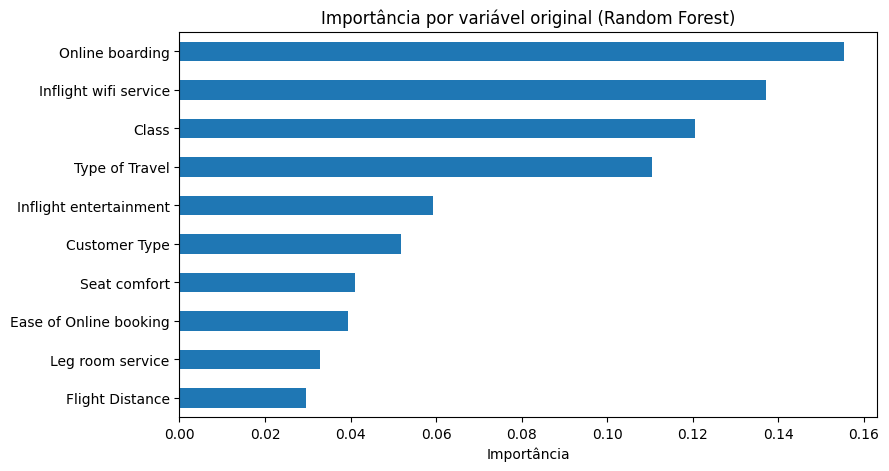

Online boarding           0.155
Inflight wifi service     0.137
Class                     0.120
Type of Travel            0.110
Inflight entertainment    0.059
Customer Type             0.052
Seat comfort              0.041
Ease of Online booking    0.039
Leg room service          0.033
Flight Distance           0.030
dtype: float64


In [ ]:
import matplotlib.pyplot as plt

rf = pipes_finais["Random Forest"]
nomes = rf.named_steps["preprocessamento"].get_feature_names_out()
imp = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nomes)

def variavel_original(n):
    n = n.split("__", 1)[1]
    for c in colunas_categoricas:
        if n.startswith(c + "_"):
            return c
    return n

imp_agr = imp.groupby(imp.index.map(variavel_original)).sum().sort_values(ascending=False)

imp_agr.head(10)[::-1].plot(kind="barh", figsize=(9, 5),
                            title="Importância por variável original (Random Forest)")
plt.xlabel("Importância")
plt.show()
print(imp_agr.head(10).round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


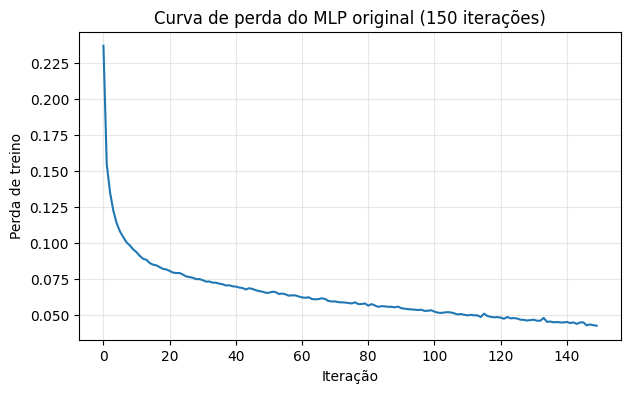

In [ ]:
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier

mlp_original = Pipeline([
    ("preprocessamento", preprocessamento),
    ("modelo", MLPClassifier(hidden_layer_sizes=(100, 50), activation="relu",
                             solver="adam", max_iter=150, random_state=42,
                             early_stopping=False, learning_rate_init=0.001))
])
mlp_original.fit(X_treino, y_treino)

rede = mlp_original.named_steps["modelo"]
plt.figure(figsize=(7, 4))
plt.plot(rede.loss_curve_)
plt.xlabel("Iteração")
plt.ylabel("Perda de treino")
plt.title("Curva de perda do MLP original (150 iterações)")
plt.grid(alpha=0.3)
plt.show()

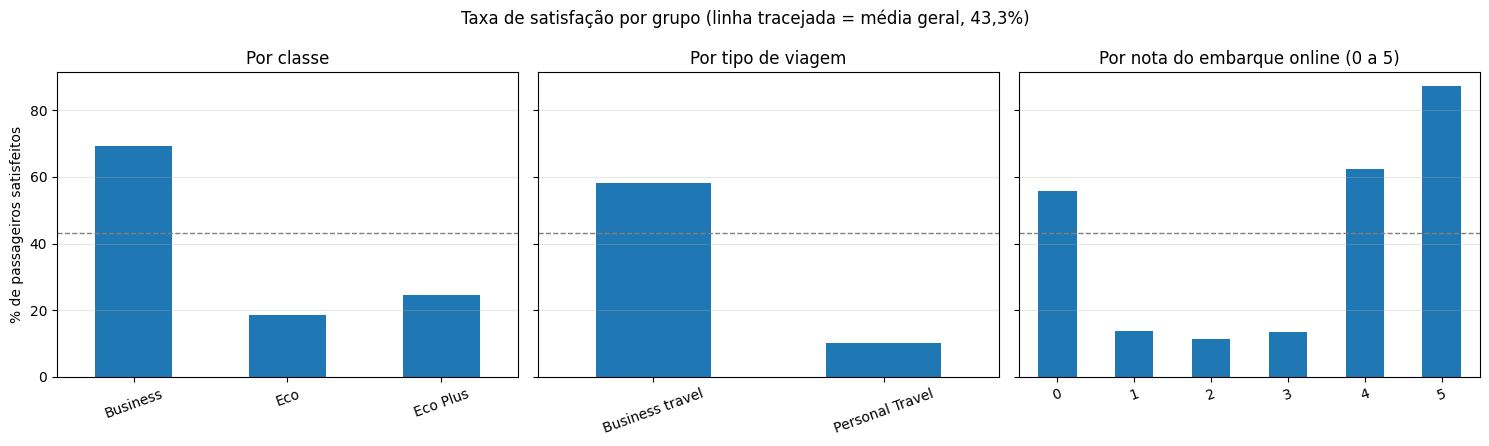

In [ ]:
import matplotlib.pyplot as plt

alvo = (df["satisfaction"] == "satisfied")
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, col, titulo in zip(
    eixos,
    ["Class", "Type of Travel", "Online boarding"],
    ["Por classe", "Por tipo de viagem", "Por nota do embarque online (0 a 5)"],
):
    taxa = alvo.groupby(df[col]).mean() * 100
    taxa.plot(kind="bar", ax=ax, rot=20)
    ax.axhline(alvo.mean() * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)

eixos[0].set_ylabel("% de passageiros satisfeitos")
fig.suptitle("Taxa de satisfação por grupo (linha tracejada = média geral, 43,3%)")
plt.tight_layout()
plt.show()

## Conclusão Final

Foram comparados sete modelos com o mesmo pré-processamento e a mesma divisão estratificada 80/20 (random_state=42): Decision Tree, Random Forest, Gradient Boosting (HistGradientBoosting), SVM com kernel RBF, Rede Neural MLP, KNN e Regressão Logística.

O melhor desempenho foi do Gradient Boosting, com 96,52% de acurácia e 96,29% de acurácia balanceada, seguido de perto pela Random Forest (96,38% e 96,17%) e pela Rede Neural MLP ajustada (96,18% e 95,88%). A diferença entre os três primeiros é menor que 0,5 ponto e, com uma única divisão treino/teste, não é conclusiva. O ranking foi o mesmo no ROC AUC. Depois vieram SVM RBF (95,32%), Decision Tree (94,59%), KNN (92,96%) e Regressão Logística (87,65%).

A primeira versão do MLP apresentou sobreajuste (98,49% no treino e 95,42% no teste). Com parada antecipada, a acurácia no teste subiu para 96,18%.

Entre as variáveis, as mais relevantes para a Random Forest foram Online boarding, Inflight wifi service, Class e Type of Travel. Isso indica o peso na previsão, não causa.

Limitações: divisão única treino/teste; SVM treinado com 30 mil dos 83 mil registros de treino; hiperparâmetros ajustados por busca apenas no SVM e, de forma simples, no MLP.
